In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("student_performance_cleaned.csv")

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Result
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,Pass
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,Pass
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,Pass


In [4]:
print("Data Set Shape:",df.shape)
print(df.columns.tolist())

Data Set Shape: (649, 34)
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'Result']


In [5]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [6]:
# statistical Anakysis
df.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [7]:
# missing Value
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
Result        0
dtype: int64


In [8]:
# No Missing Vakue  Found

In [9]:
print("Duplicate Values:",df.duplicated().sum())

Duplicate Values: 0


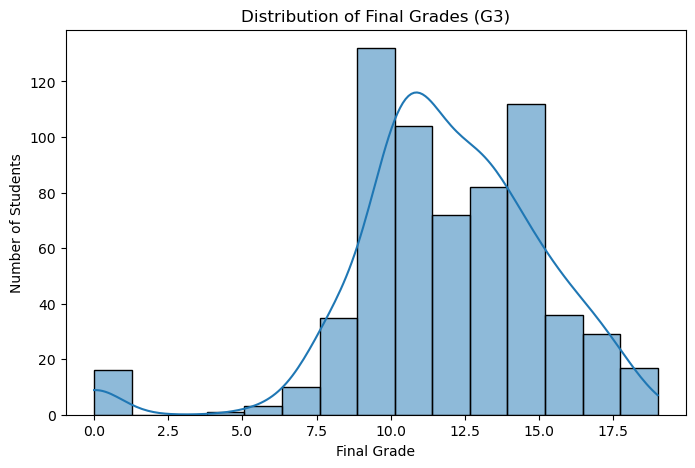

In [10]:

# Final grade Distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()


In [11]:
# Average Greade By Gemder
gender_grade = df.groupby("sex")["G3"].mean()

print(gender_grade)

sex
F    12.253264
M    11.406015
Name: G3, dtype: float64


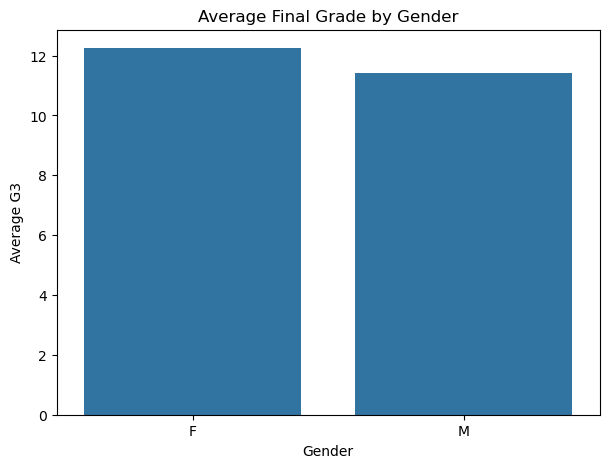

In [13]:
# By Graphical representataion Bar PLOT
plt.figure(figsize=(7, 5))

sns.barplot(x=gender_grade.index, y=gender_grade.values)

plt.title("Average Final Grade by Gender")
plt.xlabel("Gender")
plt.ylabel("Average G3")

plt.show()

In [14]:
# Study Time Vs Final Grade
study_grade = df.groupby("studytime")["G3"].mean()

print(study_grade)

studytime
1    10.844340
2    12.091803
3    13.226804
4    13.057143
Name: G3, dtype: float64


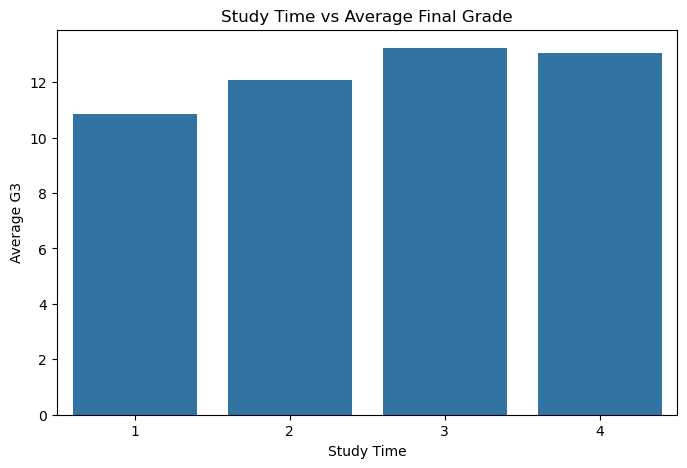

In [16]:
# By graphical Representation 
plt.figure(figsize=(8, 5))

sns.barplot(x=study_grade.index, y=study_grade.values)

plt.title("Study Time vs Average Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Average G3")

plt.show()

In [18]:
# Failure Vs Final Grade
failure_grade = df.groupby("failures")["G3"].mean()

print(failure_grade)

failures
0    12.510018
1     8.642857
2     8.812500
3     8.071429
Name: G3, dtype: float64


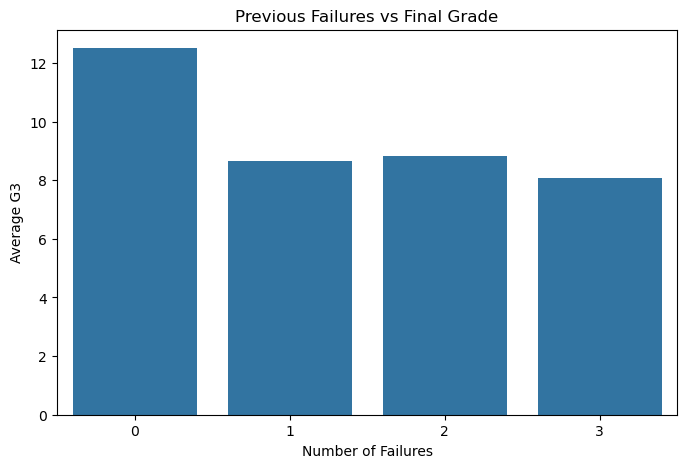

In [19]:
# By Graphical Representataion
plt.figure(figsize=(8, 5))

sns.barplot(x=failure_grade.index, y=failure_grade.values)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Number of Failures")
plt.ylabel("Average G3")

plt.show()

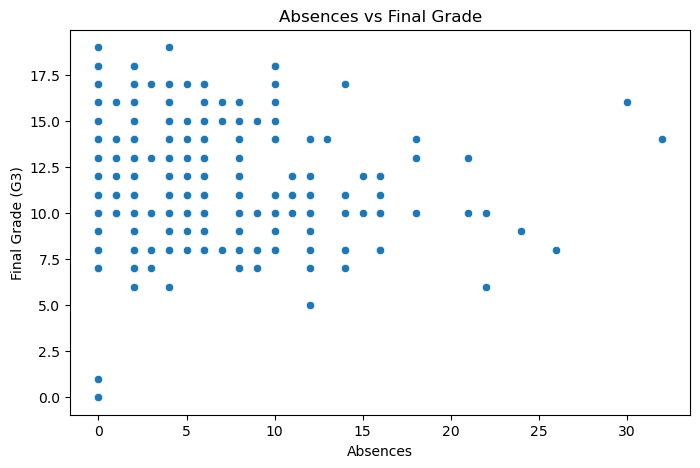

In [20]:
# Absence Vs Final Grade
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.xlabel("Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

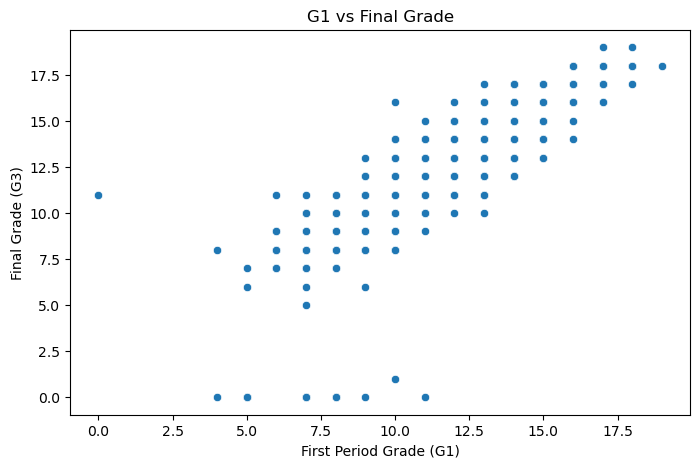

In [21]:
# Grade Representation
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="G1",
    y="G3"
)

plt.title("G1 vs Final Grade")
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Final Grade (G3)")

plt.show()

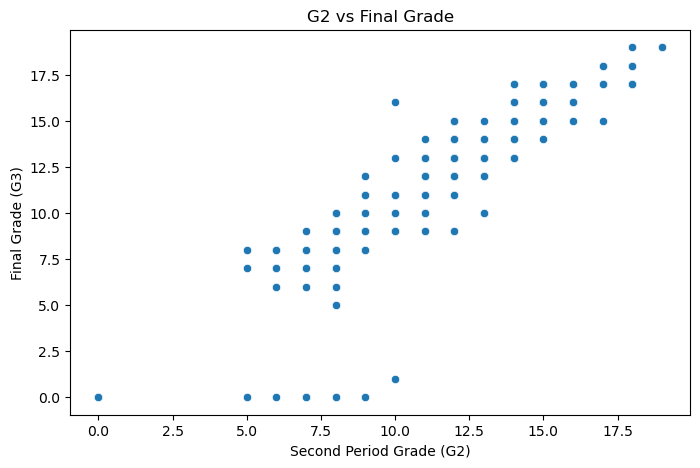

In [22]:
# G2 VS G3
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="G2",
    y="G3"
)

plt.title("G2 vs Final Grade")
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")

plt.show()

In [23]:
# Correlation anALYSIS
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc         -0.204719
failures     -0.393316
Name: G3, dtype: float64

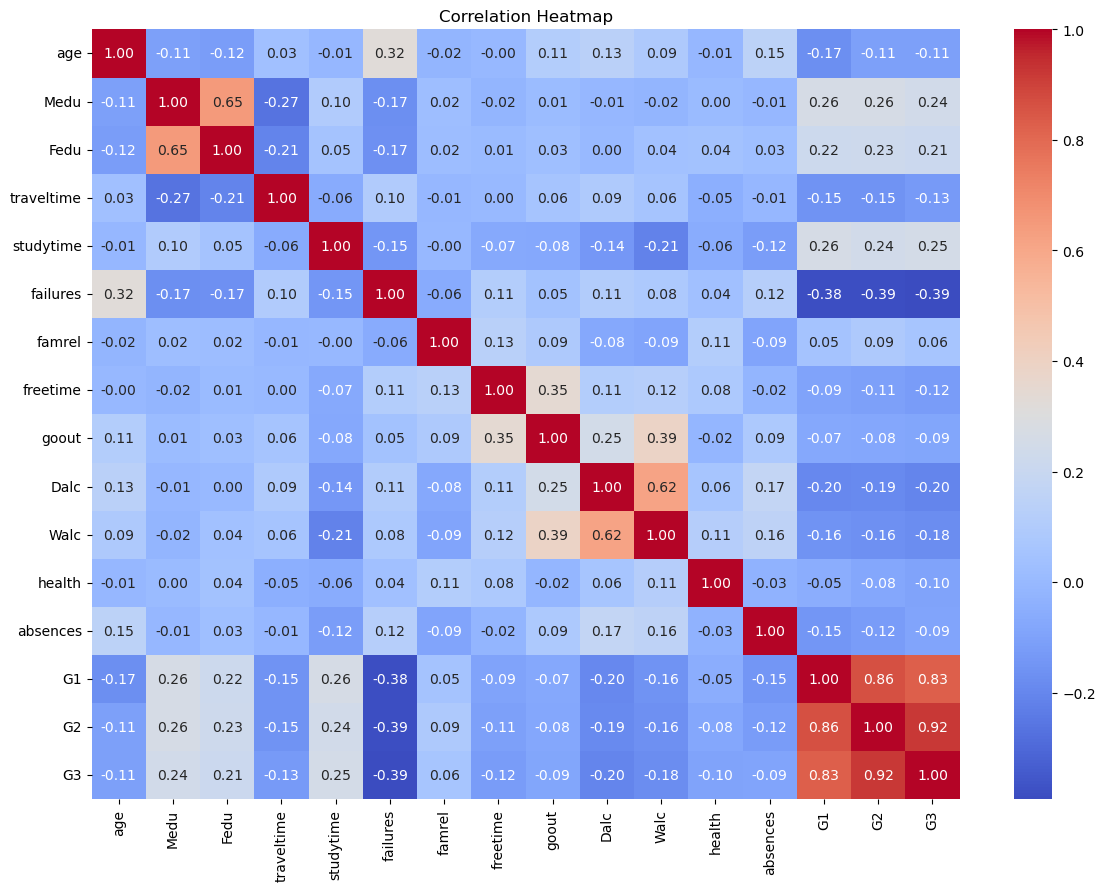

In [25]:
# Correlation Heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [28]:
# Prepare feature Target
X = df.drop(["G3", "Result"], axis=1)

y = df["G3"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)


Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Target:
G3


In [29]:
# identifing Numerical aND categorical data
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical Columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [30]:
# Creating Preprocessing Pieline
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

In [31]:
# training and Testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (519, 32)
Testing Data: (130, 32)


In [32]:
# Linear REgression Model
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

In [33]:
# evaluating Linear Regression
mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression
-------------------------
MAE : 0.7650597682758266
RMSE: 1.214870057398705
R²  : 0.8486513286537314


In [34]:
# Random forest Model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [35]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("-------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest
-------------------------
MAE : 0.7434999999999998
RMSE: 1.236557488787692
R²  : 0.8431994505594524


In [36]:
# Random forset model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [37]:
# Evaluating Random Forset
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("-------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest
-------------------------
MAE : 0.7434999999999998
RMSE: 1.236557488787692
R²  : 0.8431994505594524


In [38]:
# Gradient Boost Model
gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

In [39]:
# Evaluate Gradient Model
mae_gb = mean_absolute_error(y_test, y_pred_gb)

rmse_gb = np.sqrt(
    mean_squared_error(y_test, y_pred_gb)
)

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("-------------------------")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting
-------------------------
MAE : 0.8117477870214567
RMSE: 1.3479741698575471
R²  : 0.8136702948472542


In [41]:
# Comparing Models
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_linear,
        r2_rf,
        r2_gb
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.765060,1.214870,0.848651
1,Random Forest,0.743500,1.236557,0.843199
2,Gradient Boosting,0.811748,1.347974,0.813670


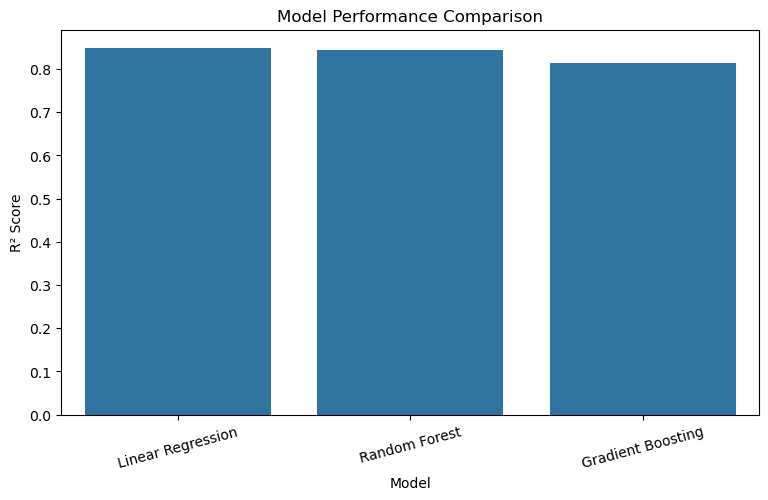

In [42]:
# Visualizing the model
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

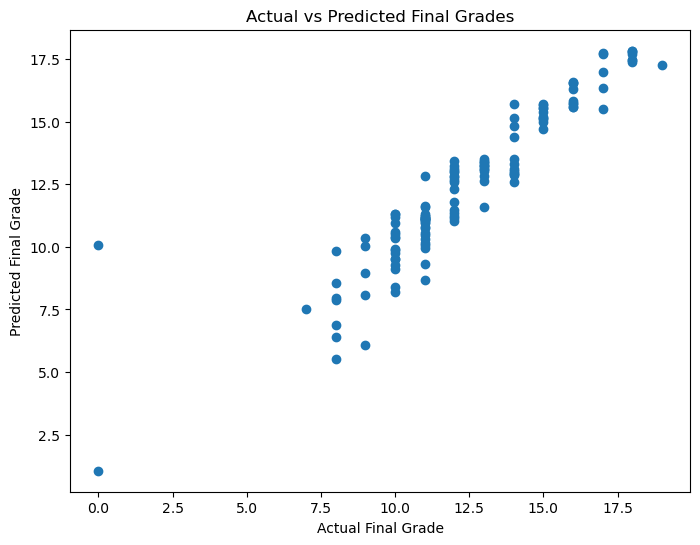

In [43]:
# Actual Vs Predicted value
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf
)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")

plt.title("Actual vs Predicted Final Grades")

plt.show()

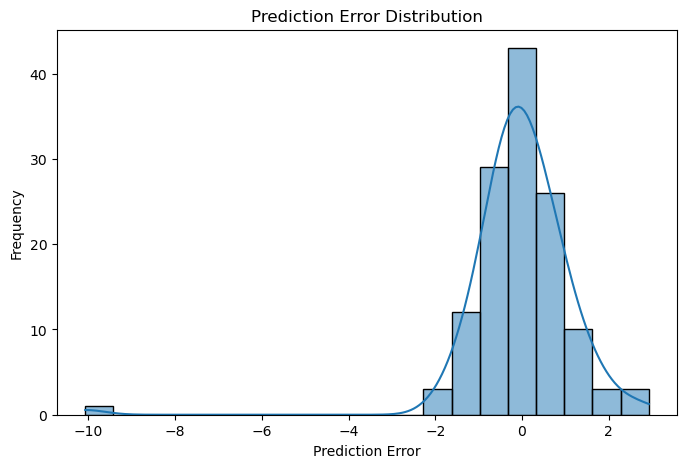

In [44]:
#Prediction Error
errors = y_test - y_pred_rf

plt.figure(figsize=(8, 5))

sns.histplot(
    errors,
    bins=20,
    kde=True
)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

In [45]:
# feature importance
preprocessor_fitted = rf_model.named_steps["preprocessor"]

rf = rf_model.named_steps["model"]

In [46]:
# Transforming Feature Name
feature_names = preprocessor_fitted.get_feature_names_out()

importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
14,num__G2,0.827255
12,num__absences,0.034917
13,num__G1,0.017979
0,num__age,0.008782
1,num__Medu,0.007074
7,num__freetime,0.006967
9,num__Dalc,0.006964
6,num__famrel,0.006050
37,cat__reason_other,0.005956
8,num__goout,0.005279


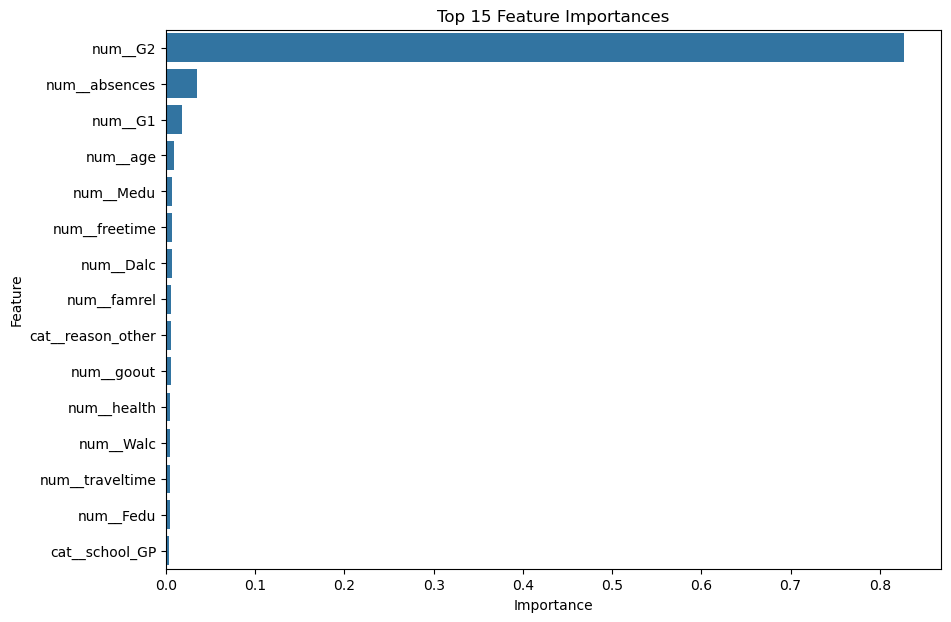

In [47]:
# Feature Importance Visualization
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [48]:
# saving Model Result
results.to_csv(
    "student_performance_model_results.csv",
    index=False
)

feature_importance.to_csv(
    "student_performance_feature_importance.csv",
    index=False
)

print("Model results saved successfully.")

Model results saved successfully.
